In [80]:
!pip install mysql-connector-python


In [137]:
import os
import mysql.connector
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

# 1. Load variables from the .env file sotred in local directory into memory
load_dotenv()

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_DATABASE = os.getenv("DB_DATABASE")

# 2. Database driver configuration function using hidden parameters
def get_raw_connection():
    return mysql.connector.connect(
        host=DB_HOST, user=DB_USER, password=DB_PASSWORD, database=DB_DATABASE
    )

# 3. Initialize connection engine
engine = create_engine("mysql+mysqlconnector://", creator=get_raw_connection)

try:
    # 4. Modify table column configurations using a context manager
    with engine.begin() as connection:
        print("Modifying table columns...")
        alter_query = text("""
        ALTER TABLE `chronic_disease_indicators`
        MODIFY COLUMN YearStart INT,
        MODIFY COLUMN LocationAbbr VARCHAR(10),
        MODIFY COLUMN Topic VARCHAR(255);
        """)
        connection.execute(alter_query)
        print("Columns modified successfully!")
    
    # 5. Execute target data selection query
    select_query = """
    SELECT YearStart, LocationDesc, Question, DataValue, ResponseID
    FROM `chronic_disease_indicators` 
    WHERE Topic = 'Diabetes' AND DataValue IS NOT NULL 
    LIMIT 30;
    """
    
    df = pd.read_sql_query(select_query, engine)
    display(df)
    
    # 6. Save the file locally on computer
    file_name = "diabetes_indicators.csv"
    df.to_csv(file_name, index=False)
    print(f"\n🟢 File successfully saved locally as '{file_name}'")

except Exception as e:
    print(f"Error: {e}")
finally:
    # Release engine connection resources automatically
    engine.dispose()


Modifying table columns...
Columns modified successfully!


,YearStart,LocationDesc,Question,DataValue,ResponseID
0,2023,United States,Diabetes among adults,23.5,59
1,2021,Iowa,Diabetes among adults,8.7,19
2,2021,Maine,Diabetes among adults,8.6,23
3,2022,Hawaii,Diabetes among adults,10.4,15
4,2023,Hawaii,Diabetes among adults,10.7,15
5,2023,Vermont,Diabetes among adults,8.5,50
6,2019,Texas,Diabetes among adults,26.7,48
7,2021,Wisconsin,Diabetes among adults,8.7,55
8,2019,Louisiana,Diabetes among adults,12.6,22
9,2019,Pennsylvania,Diabetes among adults,10.8,42



🟢 File successfully saved locally as 'diabetes_indicators.csv'


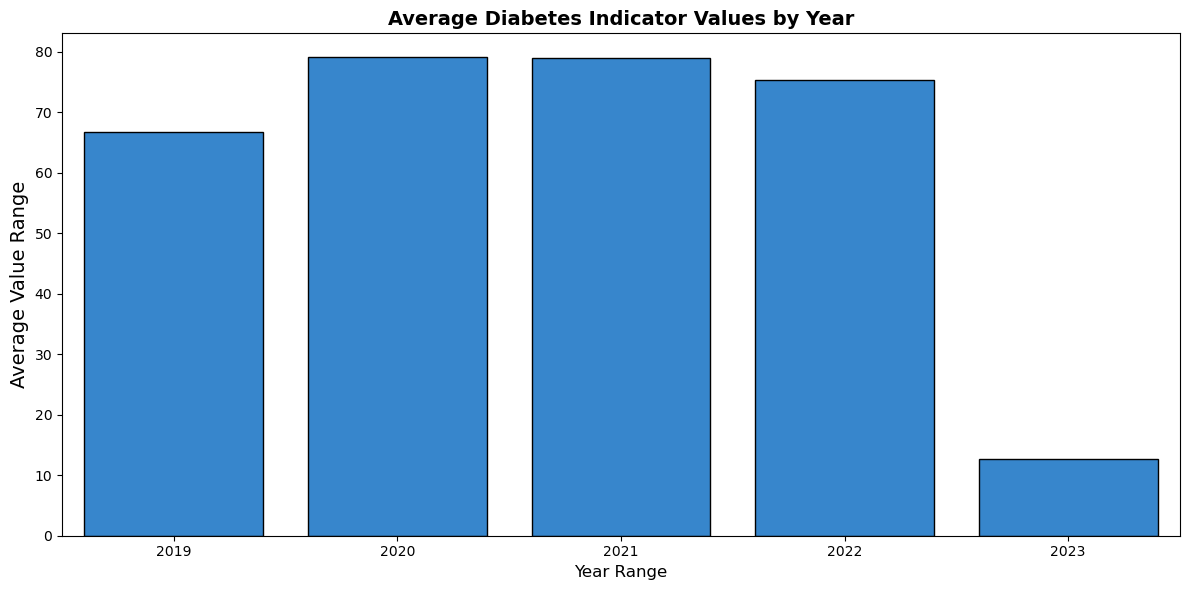

In [147]:
import os
import matplotlib.pyplot as plt
import mysql.connector
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

# 1. Load the variables from the hidden .env file into memory
load_dotenv()

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_DATABASE = os.getenv("DB_DATABASE")

# 2. Database driver configuration function using hidden parameters
def get_raw_connection():
    return mysql.connector.connect(
        host=DB_HOST, user=DB_USER, password=DB_PASSWORD, database=DB_DATABASE
    )

# 3. Initialize connection engine cleanly
engine = create_engine("mysql+mysqlconnector://", creator=get_raw_connection)

try:
    # 4. Data for Diabetes (Now using the secure connection engine)
    query = """
    SELECT YearStart, DataValue 
    FROM `chronic_disease_indicators` 
    WHERE Topic = 'Diabetes' AND DataValue IS NOT NULL;
    """
    df = pd.read_sql_query(query, engine)
    
    # 5. Clean Data: values to numbers
    df['DataValue'] = pd.to_numeric(df['DataValue'], errors='coerce')
    df = df.dropna(subset=['DataValue'])
    
    # 6. Calculate the Average Diabetes Value per Year
    df_grouped = df.groupby('YearStart')['DataValue'].mean().reset_index()
    
    # 7. Create the Bar Chart
    plt.figure(figsize=(12, 6))
    
    sns.barplot(
        data=df_grouped, 
        x='YearStart', 
        y='DataValue', 
        color='#1E88E5', 
        edgecolor='black'
    )
    
    # 8. Customize the chart labels and layout
    plt.title('Average Diabetes Indicator Values by Year', fontsize=14, fontweight='bold')
    plt.xlabel('Year Range', fontsize=12)
    plt.ylabel('Average Value Range', fontsize=14)
    plt.xticks(rotation=0)
    
    # 9. Display the chart
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error: {e}")
finally:
    engine.dispose()


Extracting features from MySQL for machine learning...
Data successfully pulled. Total rows for modeling: 7,623

--- Applying Feature Engineering Transforms ---
✔ Location target encoding applied.
✔ Transformed tracking layout (Baseline year 0 = 2019).
Training Matrix Specifications: (4179, 18)

Training the Random Forest Regressor model with engineered features...
Model training complete!

================ NEW MODEL PERFORMANCE ================
Mean Absolute Error (MAE): 1.89%
R-squared (R²) Score: 0.7098


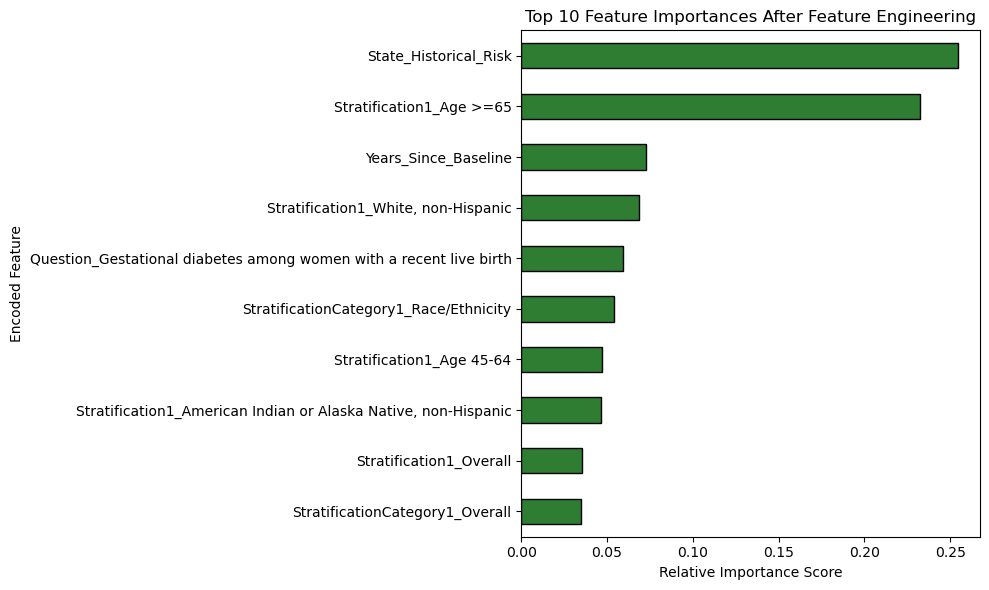

Database connection pool released.


In [134]:
import os
import matplotlib.pyplot as plt
import mysql.connector
import pandas as pd
from dotenv import load_dotenv
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sqlalchemy import create_engine

# 1. Load the secret variables from the hidden .env file into memory
load_dotenv()

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_DATABASE = os.getenv("DB_DATABASE")

# 2. Database driver configuration function using hidden parameters
def get_raw_connection():
    return mysql.connector.connect(
        host=DB_HOST, user=DB_USER, password=DB_PASSWORD, database=DB_DATABASE
    )

# 3. Initialize engine safely
engine = create_engine("mysql+mysqlconnector://", creator=get_raw_connection)

try:
    # 4. Pull target rows from the database
    query = """
    SELECT YearStart, LocationDesc, Question, DataValue, 
           StratificationCategory1, Stratification1
    FROM `chronic_disease_indicators` 
    WHERE Topic = 'Diabetes' 
      AND DataValue IS NOT NULL 
      AND DataValueUnit = '%'; 
    """
    print("Extracting features from MySQL for machine learning...")
    df = pd.read_sql_query(query, engine)
    print(f"Data successfully pulled. Total rows for modeling: {len(df):,}")

    # 5. Clean Data: Handle type casting safely
    df["DataValue"] = pd.to_numeric(df["DataValue"], errors="coerce")
    df = df.dropna(subset=["DataValue"])

    print("\n--- Applying Feature Engineering Transforms ---")
    
    # Feature 1: Target Encoding for Locations
    state_risk_map = df.groupby('LocationDesc')['DataValue'].median().to_dict()
    df['State_Historical_Risk'] = df['LocationDesc'].map(state_risk_map)
    print("✔ Location target encoding applied.")

    # Feature 2: Time Delta Translation
    min_year = df['YearStart'].min()
    df['Years_Since_Baseline'] = df['YearStart'] - min_year
    print(f"✔ Transformed tracking layout (Baseline year 0 = {min_year}).")

    # 6. Build feature matrices using optimized engineering fields
    feature_cols = [
        'Years_Since_Baseline', 
        'State_Historical_Risk', 
        'Question', 
        'StratificationCategory1', 
        'Stratification1'
    ]
    X = df[feature_cols]
    y = df["DataValue"]

    # Convert text tracking parameters into binary elements
    X_encoded = pd.get_dummies(X, drop_first=True)

    # 7. Split data into Training set (80%) and Testing set (20%)
    X_train, X_test, y_train, y_test = train_test_split(
        X_encoded, y, test_size=0.2, random_state=42
    )
    print(f"Training Matrix Specifications: {X_train.shape}")

    # 8. Train the Machine Learning Model
    print("\nTraining the Random Forest Regressor model with engineered features...")
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    print("Model training complete!")

    # 9. Evaluate Model Performance
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print("\n================ NEW MODEL PERFORMANCE ================")
    print(f"Mean Absolute Error (MAE): {mae:.2f}%")
    print(f"R-squared (R²) Score: {r2:.4f}")
    print("=======================================================")

    # 10. Plot Feature Importances
    importances = model.feature_importances_
    feat_importances = pd.Series(importances, index=X_encoded.columns)

    plt.figure(figsize=(10, 6))
    feat_importances.nlargest(10).plot(kind="barh", color="#2E7D32", edgecolor="black")
    plt.title("Top 10 Feature Importances After Feature Engineering")
    plt.xlabel("Relative Importance Score")
    plt.ylabel("Encoded Feature")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error during ML pipeline: {e}")
finally:
    engine.dispose()
    print("Database connection pool released.")


In [133]:
import os
import mysql.connector
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sqlalchemy import create_engine
from dotenv import load_dotenv

# 1. Load hidden variables from your .env file
load_dotenv()

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_DATABASE = os.getenv("DB_DATABASE")

# 2. Database Connection Engine using hidden credentials
engine = create_engine("mysql+mysqlconnector://", creator=lambda: mysql.connector.connect(
    host=DB_HOST, 
    user=DB_USER, 
    password=DB_PASSWORD, 
    database=DB_DATABASE
))

try:
    # 2. Extract and Process Data
    query = "SELECT YearStart, LocationDesc, Question, DataValue FROM chronic_disease_indicators WHERE Topic = 'Diabetes' AND DataValue IS NOT NULL AND DataValueUnit = '%';"
    df = pd.read_sql_query(query, engine)
    df["DataValue"] = pd.to_numeric(df["DataValue"], errors="coerce")
    df = df.dropna()

    # 3. Identify the Latest Historical Year Available
    latest_hist_year = int(df['YearStart'].max())
    print(f"Detected latest database historical data year: {latest_hist_year}")

    # 4. Feature Engineering
    min_year = df['YearStart'].min()
    state_map = df.groupby('LocationDesc')['DataValue'].median().to_dict()
    df['State_Historical_Risk'] = df['LocationDesc'].map(state_map)
    df['Years_Since_Baseline'] = df['YearStart'] - min_year

    # 5. Extract the Actual Present Values (Latest Historical Year)
    states = ['California', 'Texas', 'New York', 'Florida', 'Illinois']
    df_present = df[(df['YearStart'] == latest_hist_year) & (df['LocationDesc'].isin(states))]
    
    # Calculate average actual rate per state for the present year
    present_table = df_present.groupby('LocationDesc')['DataValue'].mean().round(2).to_frame()
    present_table.columns = [f'{latest_hist_year} (Actual Present)']

    # 6. Train Production Model
    features = ['Years_Since_Baseline', 'State_Historical_Risk', 'Question']
    X_hist = pd.get_dummies(df[features], drop_first=True)
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_hist, df["DataValue"])

    # 7. Generate Future Grid (2027 - 2035)
    years = list(range(2027, 2036))
    
    # FIX: Extract the raw string string value from the mode Series using .iloc[0]
    most_common_question = df['Question'].mode().iloc[0]

    future_data = [{
        'Years_Since_Baseline': y - min_year,
        'YearStart': y,
        'LocationDesc': s,
        'State_Historical_Risk': state_map[s],
        'Question': most_common_question
    } for s in states if s in state_map for y in years]

    df_future = pd.DataFrame(future_data)

    # 8. Predict Future Rates
    X_future = pd.get_dummies(df_future[features], drop_first=True).reindex(columns=X_hist.columns, fill_value=0)
    df_future['Predicted_Rate (%)'] = model.predict(X_future).round(2)

    # 9. Pivot Predictions and Merge with Present Data
    prediction_table = df_future.pivot(index='LocationDesc', columns='YearStart', values='Predicted_Rate (%)')
    
    # Rename columns to show they are model predictions
    prediction_table.columns = [f'{col} (Predicted)' for col in prediction_table.columns]
    
    # Concatenate the tables side-by-side
    comparison_table = pd.concat([present_table, prediction_table], axis=1)
    
    print("\n================ PRESENT VS PREDICTION DIABETES MATRIX ================")
    display(comparison_table)
    print("=======================================================================")

    # 10. Save to CSV file
    comparison_table.to_csv("diabetes_present_vs_prediction.csv")
    print("🟢 Saved successfully to 'diabetes_present_vs_prediction.csv'")

except Exception as e:
    print(f"❌ Forecast Engine Failure: {e}")
finally:
    engine.dispose()


Detected latest database historical data year: 2023

================ PRESENT VS PREDICTION DIABETES MATRIX ================


,2023 (Actual Present),2027 (Predicted),2028 (Predicted),2029 (Predicted),2030 (Predicted),2031 (Predicted),2032 (Predicted),2033 (Predicted),2034 (Predicted),2035 (Predicted)
LocationDesc,,,,,,,,,,
California,11.74,12.06,12.06,12.06,12.06,12.06,12.06,12.06,12.06,12.06
Florida,12.08,12.44,12.44,12.44,12.44,12.44,12.44,12.44,12.44,12.44
Illinois,13.43,12.18,12.18,12.18,12.18,12.18,12.18,12.18,12.18,12.18
New York,10.88,12.18,12.18,12.18,12.18,12.18,12.18,12.18,12.18,12.18
Texas,13.08,13.10,13.10,13.10,13.10,13.10,13.10,13.10,13.10,13.10


🟢 Saved successfully to 'diabetes_present_vs_prediction.csv'
